# Работа с данными бизнеса в ClickHouse

## Задание 1

Для начала продакт-менеджер хочет понять, где сервис пользуется наибольшей популярностью. Выведите топ-20 городов и регионов России по суммарному количеству прочитанных и прослушанных часов любого контента с мобильных устройств. Для каждой из платформ — iOS и Android — добавьте отдельный столбец с длительностью. Результат должен выглядеть так: город, общая длительность прочитанного и прослушанного контента, длительность на iOS, длительность на Android. Значения округлите до целых чисел для лучшей читаемости. Из выдачи также исключите федеральные округа — оставьте только города и области.

In [ ]:
SELECT 
    usage_geo_id_name AS city,
    ROUND(SUM(hours)) AS total_hours,
    ROUND(SUM(CASE WHEN usage_platform_ru = 'Букмейт iOS' THEN hours ELSE 0 END)) AS ios_hours,
    ROUND(SUM(CASE WHEN usage_platform_ru = 'Букмейт Android' THEN hours ELSE 0 END)) AS android_hours
FROM source_db.audition
WHERE usage_country_name = 'Россия'
    AND lower(usage_geo_id_name) NOT LIKE '%федеральный округ%'
    AND usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
GROUP BY usage_geo_id_name
ORDER BY total_hours DESC
LIMIT 20;

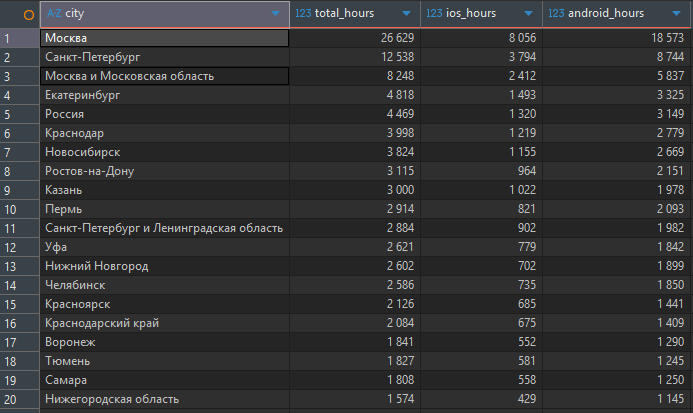

## Задание 2

С активными регионами определились, а какой контент самый популярный? Получите топ-5 книг по суммарному количеству прочитанных и прослушанных часов на мобильных платформах. Также вычислите среднее время чтения и прослушивания в зависимости от типа книги: текст или аудио. Результат должен выглядеть так: название книги, её автор, суммарное время чтения и прослушивания, среднее время чтения текстовой книги, среднее время прослушивания аудиокниги.
В список включайте только те книги, которые используются в обоих форматах. Числовые значения округляйте до двух знаков после точки.

In [ ]:
SELECT 
    c.main_content_name,
    c.main_author_name,
    ROUND(SUM(a.hours), 2) AS total_hours,
    ROUND(AVG(CASE WHEN c.main_content_type = 'Book' THEN a.hours END), 2) AS avg_text_hours,
    ROUND(AVG(CASE WHEN c.main_content_type = 'Audiobook' THEN a.hours END), 2) AS avg_audio_hours
FROM source_db.audition a
JOIN source_db.content c ON a.main_content_id = c.main_content_id
WHERE a.usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
    AND c.main_content_type IN ('Book', 'Audiobook')
GROUP BY c.main_content_name, c.main_author_name
HAVING COUNT(DISTINCT c.main_content_type) = 2
ORDER BY total_hours DESC
LIMIT 5;

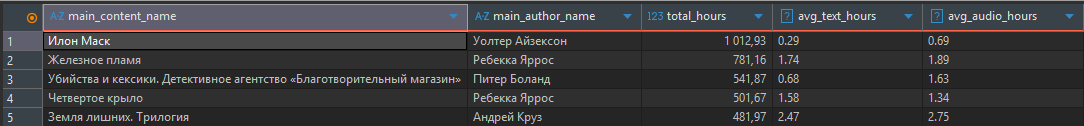

## Задание 3

Составьте топ-10 авторов по суммарной длительности чтения их книг на всех платформах, включая веб. Для каждого автора добавьте количество уникальных текстовых книг (тип контента 'Book' ) и выведите среднюю длительность прослушивания их аудиокниг только на мобильных устройствах. Исключите авторов, у которых нет аудиокниг.

In [ ]:
SELECT 
    c.main_author_name,
    ROUND(SUM(CASE WHEN c.main_content_type = 'Book' THEN a.hours ELSE 0 END), 2) AS total_reading_hours,
    COUNT(DISTINCT CASE WHEN c.main_content_type = 'Book' THEN c.main_content_id END) AS unique_text_books,
    ROUND(AVG(CASE 
        WHEN c.main_content_type = 'Audiobook' 
        AND a.usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android') 
        THEN a.hours END), 2) AS avg_audio_hours_mobile
FROM source_db.audition a
JOIN source_db.content c ON a.main_content_id = c.main_content_id
WHERE a.usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android', 'Букмейт Web') AND c.main_content_type IN ('Book', 'Audiobook')
GROUP BY c.main_author_name
HAVING COUNT(DISTINCT CASE WHEN c.main_content_type = 'Audiobook' THEN c.main_content_id END) > 0
ORDER BY total_reading_hours DESC
LIMIT 10;

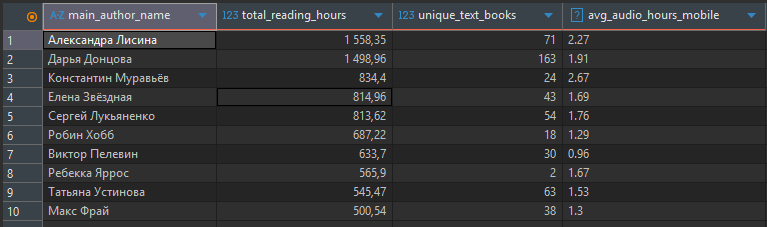

## Задание 4

У продакт-менеджера есть предположение, что среди Android-пользователей аудиокниги почти так же популярны, как тексты. А среди iOS-пользователей читателей книг вдвое больше, чем слушателей, если считать по суммарной длительности сессии.
Проверьте предположение менеджера. Для начала выделите три сегмента пользователей:
«Слушатель» — тот, кто преимущественно пользуется аудиокнигами. Прослушивание книг составляет 70% и выше от суммарной длительности сессий.
«Читатель» — преимущественно пользуется текстовыми книгами. Чтение книг — от 70%.
«Оба» — остальные пользователи сервиса.
Исключите пользователей, у которых нет сессий ни с книгами, ни с аудиокнигами, и посчитайте количество пользователей в каждом из сегментов.
На основе полученных данных проверьте предположение менеджера о том, что среди пользователей Android примерно одинаковое количество читателей и слушателей, а на устройствах iOS читателей книг вдвое больше, чем слушателей. Чтобы определить основную платформу пользователя, учитывайте время её использования. Например, если пользователь посещал сервис с двух устройств: два часа на iOS и пять часов на Android, то основной платформой такого пользователя будет Android.

In [ ]:
WITH user_platform_hours AS (
    SELECT 
        puid,
        usage_platform_ru,
        SUM(hours) as platform_hours
    FROM source_db.audition
    WHERE usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
    GROUP BY puid, usage_platform_ru
),
main_platform AS (
    SELECT 
        puid,
        usage_platform_ru
    FROM (
        SELECT 
            puid,
            usage_platform_ru,
            ROW_NUMBER() OVER (PARTITION BY puid ORDER BY platform_hours DESC) as rn
        FROM user_platform_hours
    )
    WHERE rn = 1
),
user_segments AS (
    SELECT 
        a.puid,
        mp.usage_platform_ru AS platform,
        SUM(CASE WHEN c.main_content_type = 'Audiobook' THEN a.hours ELSE 0 END) as audio_hours,
        SUM(CASE WHEN c.main_content_type = 'Book' THEN a.hours ELSE 0 END) as book_hours,
        SUM(CASE WHEN c.main_content_type IN ('Book', 'Audiobook') THEN a.hours ELSE 0 END) as total_book_hours,
        CASE 
            WHEN SUM(CASE WHEN c.main_content_type = 'Audiobook' THEN a.hours ELSE 0 END) / 
                 NULLIF(SUM(CASE WHEN c.main_content_type IN ('Book', 'Audiobook') THEN a.hours ELSE 0 END), 0) >= 0.7 
            THEN 'Слушатель'
            WHEN SUM(CASE WHEN c.main_content_type = 'Book' THEN a.hours ELSE 0 END) / 
                 NULLIF(SUM(CASE WHEN c.main_content_type IN ('Book', 'Audiobook') THEN a.hours ELSE 0 END), 0) >= 0.7 
            THEN 'Читатель'
            ELSE 'Оба'
        END as segment
    FROM source_db.audition a
    JOIN source_db.content c ON a.main_content_id = c.main_content_id
    JOIN main_platform mp ON a.puid = mp.puid
    WHERE c.main_content_type IN ('Book', 'Audiobook')
    GROUP BY a.puid, mp.usage_platform_ru
    HAVING SUM(CASE WHEN c.main_content_type IN ('Book', 'Audiobook') THEN a.hours ELSE 0 END) > 0
)
SELECT 
    platform,
    segment,
    COUNT(*) as users_count
FROM user_segments
GROUP BY platform, segment
ORDER BY platform, segment;


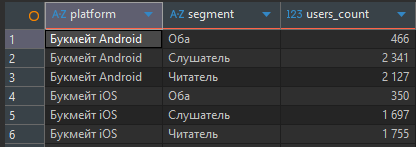

## Задание 5

Изучите, существует ли связь между форматом использования приложения (прослушивание или чтение) и днём недели. Падает ли использование аудиокниг в выходные на всех платформах, включая веб? Чтобы это узнать, для каждого типа контента посчитайте среднее время его использования в рабочие и выходные дни и округлите до целого числа. Используя оконные функции, вы также можете пользоваться и комбинаторами.

In [ ]:
SELECT 
    c.main_content_type,
    CASE 
        WHEN toDayOfWeek(a.msk_business_dt_str) IN (6, 7) THEN 'weekend'
        ELSE 'weekday'
    END as day_type,
    ROUND(AVG(a.hours)) as avg_hours
FROM source_db.audition a
JOIN source_db.content c ON a.main_content_id = c.main_content_id
WHERE a.usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android', 'Букмейт Web') 
	AND c.main_content_type IN ('Book', 'Audiobook')
GROUP BY c.main_content_type, day_type
ORDER BY c.main_content_type, day_type;

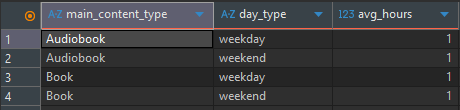

## Задание 6

Продакт-менеджер хочет отслеживать обновления приложений на Android и iOS. У него есть предположение, что больший процент пользователей iOS используют последнюю версию приложения и в целом чаще его обновляют.
Для начала изучите, у какой части пользователей на текущий момент стоят последние версии приложения на каждой из платформ. Для этого посчитайте последнюю активную версию каждого пользователя и сравните её с последней версией у каждой платформы. Для каждой платформы выведите процент пользователей с последней версией приложения и округлите его до двух знаков после точки.

In [ ]:
WITH last_versions AS (
    SELECT 
        usage_platform_ru,
        MAX(app_version) as last_version
    FROM source_db.audition
    WHERE usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
        AND app_version IS NOT NULL
    GROUP BY usage_platform_ru
),
user_last_version AS (
    SELECT 
        puid,
        usage_platform_ru,
        argMax(app_version, msk_business_dt_str) as user_last_version
    FROM source_db.audition
    WHERE usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
        AND app_version IS NOT NULL
    GROUP BY puid, usage_platform_ru
)
SELECT 
    ulv.usage_platform_ru,
    ROUND(
        COUNT(CASE WHEN ulv.user_last_version = lv.last_version THEN 1 END) * 100.0 / COUNT(*), 
        2
    ) as percent_with_last_version
FROM user_last_version ulv
JOIN last_versions lv ON ulv.usage_platform_ru = lv.usage_platform_ru
GROUP BY ulv.usage_platform_ru;

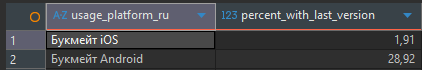

## Задание 7

Теперь продакт-менеджер хочет понять, как часто пользователи обновляют приложение на каждой из платформ. Фактом обновления считайте изменение версии у каждого пользователя. Представьте, что любое изменение возможно только в сторону более новой версии.
Проверьте предположение о том, что пользователи iOS чаще обновляют приложение. Посчитайте метрику update_rate, которая покажет среднюю частоту обновлений на пользователя. Округлите её до двух знаков после точки.

In [ ]:
SET allow_experimental_analyzer = 1;

WITH user_version_sequence AS (
    SELECT 
        puid,
        usage_platform_ru,
        app_version,
        msk_business_dt_str,
        lag(app_version) OVER (PARTITION BY puid, usage_platform_ru ORDER BY msk_business_dt_str) as prev_version
    FROM source_db.audition
    WHERE usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
        AND app_version IS NOT NULL
),
updates AS (
    SELECT 
        puid,
        usage_platform_ru,
        COUNT(*) as updates_count
    FROM user_version_sequence
    WHERE prev_version IS NOT NULL 
        AND app_version != prev_version
        AND app_version > prev_version
    GROUP BY puid, usage_platform_ru
)
SELECT 
    usage_platform_ru,
    ROUND(AVG(updates_count), 2) as update_rate
FROM updates
GROUP BY usage_platform_ru;

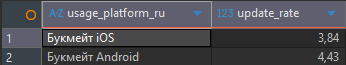

## Задание 8

Новая задача — у коллег есть опасения, что не все книги на тему магии верно размечены с точки зрения категорий.  Считается, что у книги должно быть не больше 3–4 категорий с темами. Необходимо найти все книги на магическую тему, которые при этом не входят в художественную литературу, и проверить, правильно ли они размечены.
Начните с подсчёта книг с тегом «Магия». Выведите количество таких книг в каталоге.

In [ ]:
SELECT COUNT(*) as magic_books_count
FROM source_db.content
WHERE has(published_topic_title_list, 'Магия')
    AND main_content_type = 'Book';

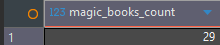

## Задание 9

Найдите все книги со словом «магия» в названии, для которых не проставлен тег «Магия». При этом не учитывайте книги с тегом «Художественная литература». Выведите количество таких книг в каталоге.

In [ ]:
SELECT COUNT(*) as books_with_magic_in_name
FROM source_db.content
WHERE lower(main_content_name) LIKE '%магия%'
    AND NOT has(published_topic_title_list, 'Магия')
    AND NOT has(published_topic_title_list, 'Художественная литература')
    AND main_content_type = 'Book';

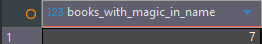

## Задание 10

Посчитайте среднее количество категорий у книг с тегом «Магия» и среднее количество категорий у книг в каталоге в целом. Округлите значения до двух знаков после точки. Напомним, что коллегам важно, чтобы у каждой книги было не больше 3–4 категорий. Получится ли не превысить рекомендованного количества?

In [ ]:
SELECT 
    ROUND(AVG(CASE WHEN has(published_topic_title_list, 'Магия') THEN length(published_topic_title_list) END), 2) as avg_categories_magic,
    ROUND(AVG(length(published_topic_title_list)), 2) as avg_categories_all
FROM source_db.content
WHERE main_content_type = 'Book';

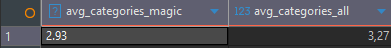

## Задание 11

Продакт-менеджер выяснил, что в приложении одной из мобильных платформ могла возникнуть проблема — длина пользовательской сессии (поле hours_sessions_long ) записывается некорректно, и это происходит как минимум в одной из стран. Чтобы найти аномалию в данных, используйте такую меру дисперсии как коэффициент вариации. Напомним его формулу: коэффициент определяется как отношение стандартного отклонения к среднему. Чем выше этот показатель, тем более подозрительно с точки зрения анализа распределены данные.
Исследуйте коэффициент по странам и мобильным платформам. В какой стране и на какой платформе видна аномалия в данных? Ограничьте выборку одной страной, в которой коэффициент вариации для одной из платформ будет наибольшим.

In [ ]:
SELECT 
    usage_country_name,
    usage_platform_ru,
    ROUND(stddevPop(hours_sessions_long) / avg(hours_sessions_long), 2) as coefficient_of_variation
FROM source_db.audition
WHERE usage_platform_ru IN ('Букмейт iOS', 'Букмейт Android')
    AND hours_sessions_long > 0
GROUP BY usage_country_name, usage_platform_ru
ORDER BY coefficient_of_variation DESC
LIMIT 10;

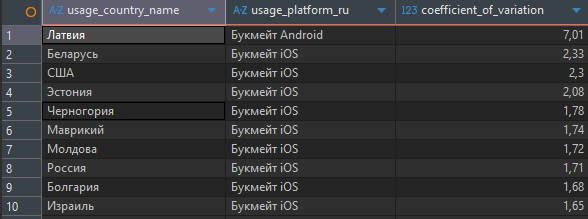